# 1 · Grafo sin modelo

**Módulo 1 · Introducción.** El proyecto del módulo es un agente de cálculo simbólico. Esta lección construye su base sin modelo de lenguaje: un grafo que ejecuta el método de Newton. Corre en CPU, sin GPU ni claves.

Se definen las piezas de un grafo de LangGraph (esquema, estado, nodo, reducer y arista), su modelo de ejecución por supersteps y las condiciones para que una ejecución termine. Corresponde a la lección *Simple graph* del curso [Intro to LangGraph](https://academy.langchain.com/courses/intro-to-langgraph) de LangChain Academy.

Requisito: `pip install "langgraph>=1.2"`. Las salidas de este notebook son de langgraph 1.2.17.

In [1]:
from importlib.metadata import version

print("langgraph", version("langgraph"))

langgraph 1.2.17


## 1. El problema

El método de Newton aproxima una raíz de una función derivable $f$ con la iteración

$$x_{n+1} = x_n - \frac{f(x_n)}{f'(x_n)}.$$

Con $f(x) = x^2 - 2$ y $x_0 = 1$, la sucesión converge a $\sqrt{2}$. El grafo de esta lección expresa esa iteración: un estado que guarda $x_n$, un nodo que aplica un paso y una arista que decide si seguir.

In [2]:
def f(x: float) -> float:
    return x**2 - 2


def df(x: float) -> float:
    return 2 * x

## 2. Esquema y estado

**Definición 1.1 (esquema).** Un esquema es un conjunto finito de claves $K$ junto con un conjunto de valores $V_k$ para cada clave $k \in K$.

**Definición 1.2 (estado).** Un estado es una función $s$ que asigna a cada clave $k \in K$ un valor $s(k) \in V_k$. El conjunto de estados es $S = \prod_{k \in K} V_k$.

El esquema es un tipo y un estado es un elemento de ese tipo. En LangGraph, el esquema se declara con un `TypedDict`: cada atributo es una clave y su anotación indica $V_k$. Un estado es un `dict` con esas claves.

Para Newton, $K = \{x, n\}$, con $V_x = \mathbb{R}$ para la aproximación actual y $V_n = \mathbb{N}$ para las iteraciones hechas.

In [3]:
from typing_extensions import TypedDict


class EstadoNewton(TypedDict):
    x: float  # aproximación actual
    n: int  # iteraciones hechas

**Observación.** La anotación documenta $V_k$, pero no se verifica: un `TypedDict` no valida tipos al ejecutar, y un nodo podría escribir un texto en `x` sin que nada falle. El módulo 2 usa Pydantic para validar.

## 3. Nodos y actualizaciones

**Definición 1.3 (actualización).** Una actualización es una función parcial $u$ de $K$ en $\bigcup_{k \in K} V_k$, con $u(k) \in V_k$ para cada $k \in \operatorname{dom}(u)$. $U$ denota el conjunto de actualizaciones.

**Definición 1.4 (nodo).** Un nodo es una función $\varphi : S \to U$. Recibe el estado completo y devuelve solo las claves que cambia.

En Python, un nodo es una función que recibe el `dict` del estado y devuelve un `dict` con algunas de sus claves. El paso de Newton cambia las dos:

In [4]:
def paso(s: EstadoNewton) -> dict:
    """Un paso de Newton: x ← x − f(x)/f′(x)."""
    x = s["x"]
    return {"x": x - f(x) / df(x), "n": s["n"] + 1}

El nodo no modifica `s`: devuelve una actualización nueva, y LangGraph la aplica.

## 4. Reducers: cómo se aplica una actualización

**Definición 1.5 (reducer).** Un reducer para la clave $k$ es una función $r_k : V_k \times V_k \to V_k$. Aplicar una actualización $u$ a un estado $s$ da el estado $s \oplus u$ definido por

$$(s \oplus u)(k) = \begin{cases} r_k\big(s(k),\, u(k)\big) & \text{si } k \in \operatorname{dom}(u), \\ s(k) & \text{si } k \notin \operatorname{dom}(u). \end{cases}$$

**Propiedad 1.6.** Si una clave no declara reducer, $r_k(a, b) = b$: el valor nuevo reemplaza al anterior. Las claves fuera de $\operatorname{dom}(u)$ no cambian.

Se comprueba con un grafo de un nodo que devuelve solo `x`. La construcción del grafo se explica en la sección 5; aquí importa el resultado.

In [5]:
from langgraph.graph import END, START, StateGraph


def solo_x(s: EstadoNewton) -> dict:
    return {"x": 1.5}


constructor = StateGraph(EstadoNewton)
constructor.add_node("solo_x", solo_x)
constructor.add_edge(START, "solo_x")
constructor.add_edge("solo_x", END)
un_nodo = constructor.compile()

un_nodo.invoke({"x": 1.0, "n": 3})

{'x': 1.5, 'n': 3}

`n` conserva su valor porque no está en el dominio de la actualización.

Un reducer se declara con `Annotated[V_k, r_k]`. Con `operator.add`, que en listas es la concatenación, la clave acumula en lugar de reemplazar. Así se puede guardar la trayectoria $(x_0, x_1, \dots)$:

In [6]:
import operator
from typing import Annotated


class EstadoConTrayectoria(TypedDict):
    x: float
    trayectoria: Annotated[list[float], operator.add]


def avanzar(s: EstadoConTrayectoria) -> dict:
    return {"x": 1.5, "trayectoria": [1.5]}


constructor = StateGraph(EstadoConTrayectoria)
constructor.add_node("avanzar", avanzar)
constructor.add_edge(START, "avanzar")
constructor.add_edge("avanzar", END)
con_trayectoria = constructor.compile()

con_trayectoria.invoke({"x": 1.0, "trayectoria": [1.0]})

{'x': 1.5, 'trayectoria': [1.0, 1.5]}

Internamente, cada clave del esquema es un **canal**, y el tipo de canal implementa su reducer: `LastValue` reemplaza y `BinaryOperatorAggregate` aplica $r_k$.

In [7]:
{
    clave: type(canal).__name__
    for clave, canal in con_trayectoria.channels.items()
    if clave in EstadoConTrayectoria.__annotations__
}

{'x': 'LastValue', 'trayectoria': 'BinaryOperatorAggregate'}

## 5. Aristas y grafo

**Definición 1.7 (grafo).** Un grafo es un par $G = (V, E)$. $V$ contiene los nodos y dos vértices especiales, `START` y `END`. Una arista es de uno de dos tipos:

- **fija**, un par $(a, b)$: después de $a$ se ejecuta $b$;
- **condicional** desde $a$, una función $c : S \to V$: evaluada en el estado que deja $a$, elige el vértice siguiente.

La ejecución parte en `START` y termina al llegar a `END`.

Para Newton, la arista condicional decide entre otro paso y el final:

$$c(s) = \begin{cases} \texttt{paso} & \text{si } |f(s(x))| \ge \varepsilon, \\ \texttt{END} & \text{si no.} \end{cases}$$

In [8]:
EPSILON = 1e-10


def continuar(s: EstadoNewton) -> str:
    return "paso" if abs(f(s["x"])) >= EPSILON else END


constructor = StateGraph(EstadoNewton)
constructor.add_node("paso", paso)
constructor.add_edge(START, "paso")
constructor.add_conditional_edges("paso", continuar, ["paso", END])
newton = constructor.compile()

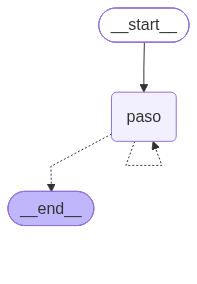

In [9]:
from IPython.display import Image, display

display(Image(newton.get_graph().draw_mermaid_png()))

`compile` valida la estructura (por ejemplo, que cada arista lleve a un nodo que existe) y devuelve el grafo ejecutable. El dibujo de `draw_mermaid_png` requiere internet, porque lo genera el servicio mermaid.ink.

El tercer argumento de `add_conditional_edges` declara la imagen de $c$, el conjunto $\{\texttt{paso}, \texttt{END}\}$. Sin él el grafo se ejecuta igual, pero LangGraph no puede deducir a dónde lleva $c$ y la descripción del grafo omite la arista `paso → paso`:

In [10]:
constructor = StateGraph(EstadoNewton)
constructor.add_node("paso", paso)
constructor.add_edge(START, "paso")
constructor.add_conditional_edges("paso", continuar)
sin_imagen = constructor.compile()


def aristas(grafo) -> list[str]:
    return sorted(
        f"{a.source} → {a.target}" + (" (condicional)" if a.conditional else "")
        for a in grafo.get_graph().edges
    )


print("con imagen:", aristas(newton))
print("sin imagen:", aristas(sin_imagen))
print("x final sin imagen:", sin_imagen.invoke({"x": 1.0, "n": 0})["x"])

con imagen: ['__start__ → paso', 'paso → __end__ (condicional)', 'paso → paso (condicional)']
sin imagen: ['__start__ → paso', 'paso → __end__']
x final sin imagen: 1.4142135623746899


## 6. Ejecución por supersteps

**Definición 1.8 (superstep).** La ejecución avanza en pasos discretos llamados supersteps. En el superstep $t$:

1. se activan los nodos que eligieron las aristas al cerrar el superstep anterior;
2. cada nodo activo $v$ lee el mismo estado $s_t$ y calcula su actualización $\varphi_v(s_t)$;
3. al cerrar el superstep se aplican las actualizaciones. Con un solo nodo activo, $s_{t+1} = s_t \oplus \varphi_v(s_t)$.

`START` también ocupa un superstep: es el que escribe la entrada en el estado. En este módulo hay un solo nodo activo por superstep. Con varios (módulo 4), todos leen el mismo $s_t$ y sus actualizaciones se combinan al cerrar el paso.

**Propiedad 1.9.** Una ejecución produce una sucesión de estados $s_0, s_1, s_2, \dots$, donde $s_0$ es la entrada. `stream` con `stream_mode="values"` entrega esa sucesión, un estado por superstep, e `invoke` devuelve el último.

In [11]:
for s in newton.stream({"x": 1.0, "n": 0}, stream_mode="values"):
    print(s)

{'x': 1.0, 'n': 0}
{'x': 1.5, 'n': 1}
{'x': 1.4166666666666667, 'n': 2}
{'x': 1.4142156862745099, 'n': 3}
{'x': 1.4142135623746899, 'n': 4}


La misma sucesión, con el error $e_n = |x_n - \sqrt{2}|$:

In [12]:
import math

for s in newton.stream({"x": 1.0, "n": 0}, stream_mode="values"):
    print(f"n = {s['n']}   x = {s['x']:.16f}   e = {abs(s['x'] - math.sqrt(2)):.1e}")

n = 0   x = 1.0000000000000000   e = 4.1e-01
n = 1   x = 1.5000000000000000   e = 8.6e-02
n = 2   x = 1.4166666666666667   e = 2.5e-03
n = 3   x = 1.4142156862745099   e = 2.1e-06
n = 4   x = 1.4142135623746899   e = 1.6e-12


Desde $n = 2$, el exponente del error se duplica en cada paso ($10^{-3}$, $10^{-6}$, $10^{-12}$): es la convergencia cuadrática de Newton cerca de una raíz simple. El ejercicio 3 estima ese orden. `invoke` entrega solo el último término:

In [13]:
newton.invoke({"x": 1.0, "n": 0})

{'x': 1.4142135623746899, 'n': 4}

## 7. Terminación

**Proposición 1.10.** Con la arista $c$ de la sección 5, la ejecución llega a `END` si y solo si existe $n \ge 1$ con $|f(x_n)| < \varepsilon$.

*Demostración.* La arista fija `START → paso` hace que el primer estado evaluado sea $s_1$. Desde ahí, $c$ se evalúa después de cada paso y elige `END` exactamente en el primer estado con $|f(x_n)| < \varepsilon$. Si ese estado no existe, elige `paso` en todos los supersteps. $\square$

Con $f(x) = x^2 + 1$, que no tiene raíces reales, ese $n$ no existe. LangGraph detiene la ejecución con `GraphRecursionError` al superar `recursion_limit` supersteps.

**Definición 1.11 (`recursion_limit`).** `recursion_limit` es la cantidad máxima de supersteps de una ejecución, contando el de `START`. Se pasa en la configuración: `invoke(entrada, {"recursion_limit": L})`. En langgraph 1.2.17 vale 10 007 por defecto. El valor está en `langgraph/_internal/_config.py` y se cambia con la variable de entorno `LANGGRAPH_DEFAULT_RECURSION_LIMIT`.

In [14]:
from langgraph.errors import GraphRecursionError


def construir_newton(g, dg, epsilon=EPSILON, cota=None):
    """Grafo de Newton para g. Con `cota`, llega a END después de a lo más `cota` pasos."""

    def paso(s: EstadoNewton) -> dict:
        x = s["x"]
        return {"x": x - g(x) / dg(x), "n": s["n"] + 1}

    def continuar(s: EstadoNewton) -> str:
        sigue = abs(g(s["x"])) >= epsilon
        if cota is not None:
            sigue = sigue and s["n"] < cota
        return "paso" if sigue else END

    constructor = StateGraph(EstadoNewton)
    constructor.add_node("paso", paso)
    constructor.add_edge(START, "paso")
    constructor.add_conditional_edges("paso", continuar, ["paso", END])
    return constructor.compile()


sin_raiz = construir_newton(lambda x: x**2 + 1, lambda x: 2 * x)
try:
    sin_raiz.invoke({"x": 0.5, "n": 0}, {"recursion_limit": 100})
except GraphRecursionError as error:
    print(type(error).__name__, "→", str(error).splitlines()[0])

GraphRecursionError → Recursion limit of 100 reached without hitting a stop condition. You can increase the limit by setting the `recursion_limit` config key.


Para $x^2 - 2$ desde $x_0 = 1$ hay 4 pasos de Newton más el superstep de `START`, así que el mínimo es $L = 5$:

In [15]:
for limite in (4, 5):
    try:
        newton.invoke({"x": 1.0, "n": 0}, {"recursion_limit": limite})
        print(f"recursion_limit = {limite}: llega a END")
    except GraphRecursionError:
        print(f"recursion_limit = {limite}: GraphRecursionError")

recursion_limit = 4: GraphRecursionError
recursion_limit = 5: llega a END


`recursion_limit` corta la ejecución con un error. Para que la ejecución termine por sí misma, la cota tiene que estar en la arista.

**Proposición 1.12.** Sea $N \ge 1$ y sea

$$c_N(s) = \begin{cases} \texttt{paso} & \text{si } |f(s(x))| \ge \varepsilon \text{ y } s(n) < N, \\ \texttt{END} & \text{si no.} \end{cases}$$

Si la entrada tiene $n = 0$, la ejecución llega a `END` después de a lo más $N$ pasos de Newton, es decir, en a lo más $N + 1$ supersteps.

*Demostración.* Cada superstep de `paso` aumenta $n$ en 1. Después de $N$ pasos, $s(n) = N$ y $c_N$ elige `END`. $\square$

In [16]:
acotado = construir_newton(lambda x: x**2 + 1, lambda x: 2 * x, cota=50)
final = acotado.invoke({"x": 0.5, "n": 0})

print(final)
print("|f(x)| < ε:", abs(final["x"] ** 2 + 1) < EPSILON)

{'x': -0.8707527744354187, 'n': 50}
|f(x)| < ε: False


Llegar a `END` no implica converger. Con la cota, el estado final tiene que revisarse: aquí $n = N = 50$ y $|f(x_{50})| \ge \varepsilon$.

## Resumen

- Un **esquema** $(K, (V_k)_{k \in K})$ es un tipo y un **estado** es un elemento de $S = \prod_{k} V_k$. En LangGraph son un `TypedDict` y un `dict`. El `TypedDict` no valida tipos.
- Un **nodo** es una función $\varphi : S \to U$ que devuelve una actualización parcial.
- $s \oplus u$ aplica el reducer de cada clave de $\operatorname{dom}(u)$. Por defecto el valor nuevo reemplaza al anterior. Cada clave es un canal: `LastValue` o `BinaryOperatorAggregate`.
- Las **aristas** fijas y condicionales ($c : S \to V$) definen qué vértice sigue. `add_conditional_edges` recibe la imagen de $c$.
- La ejecución avanza en **supersteps**: $s_{t+1} = s_t \oplus \varphi(s_t)$. `stream(..., stream_mode="values")` entrega la sucesión de estados e `invoke`, su último término.
- Un ciclo puede no terminar. `recursion_limit` acota los supersteps, `START` incluido, y vale 10 007 por defecto. Una cota en la arista garantiza llegar a `END`, pero no la convergencia.

## Ejercicios

**Ejercicio 1 (bisección).** Expresar el método de bisección como grafo: un estado con claves $a$, $b$ y $n$ que cumple $f(a)\,f(b) < 0$, un nodo que reemplaza $a$ o $b$ por el punto medio y una arista condicional que termina cuando $b - a < \varepsilon$. Probarlo con $f(x) = x^2 - 2$ en $[1, 2]$ y determinar cuántos pasos hace.

*Pista:* el invariante $f(a)\,f(b) < 0$ decide qué extremo se reemplaza.

<details>
<summary>Solución</summary>

```python
class EstadoBiseccion(TypedDict):
    a: float
    b: float
    n: int


def biseccion(s: EstadoBiseccion) -> dict:
    m = (s["a"] + s["b"]) / 2
    if f(s["a"]) * f(m) <= 0:
        return {"b": m, "n": s["n"] + 1}
    return {"a": m, "n": s["n"] + 1}


def seguir(s: EstadoBiseccion) -> str:
    return "biseccion" if s["b"] - s["a"] >= EPSILON else END


constructor = StateGraph(EstadoBiseccion)
constructor.add_node("biseccion", biseccion)
constructor.add_edge(START, "biseccion")
constructor.add_conditional_edges("biseccion", seguir, ["biseccion", END])
bisecar = constructor.compile()

bisecar.invoke({"a": 1.0, "b": 2.0, "n": 0})  # n = 34
```

El nodo devuelve solo el extremo que cambia, y la Propiedad 1.6 conserva el otro. A diferencia de Newton, la bisección siempre llega a `END` sin cota: después de $n$ pasos, $b - a = 2^{-n}(b_0 - a_0)$, así que termina con $n = \lceil \log_2((b_0 - a_0)/\varepsilon) \rceil = \lceil \log_2 10^{10} \rceil = 34$.

</details>

**Ejercicio 2 (una clave olvidada).** En `construir_newton` con `cota=50`, cambiar `paso` para que devuelva solo `{"x": ...}`. Predecir qué ocurre con $f(x) = x^2 + 1$ antes de ejecutarlo.

*Pista:* Propiedad 1.6. ¿Qué valor tiene $n$ en cada superstep?

<details>
<summary>Solución</summary>

```python
def paso_sin_n(s: EstadoNewton) -> dict:
    x = s["x"]
    return {"x": x - (x**2 + 1) / (2 * x)}


def continuar_con_cota(s: EstadoNewton) -> str:
    sigue = abs(s["x"] ** 2 + 1) >= EPSILON and s["n"] < 50
    return "paso" if sigue else END


constructor = StateGraph(EstadoNewton)
constructor.add_node("paso", paso_sin_n)
constructor.add_edge(START, "paso")
constructor.add_conditional_edges("paso", continuar_con_cota, ["paso", END])

try:
    constructor.compile().invoke({"x": 0.5, "n": 0}, {"recursion_limit": 100})
except GraphRecursionError:
    print("GraphRecursionError: n se quedó en 0")
```

`n` no está en el dominio de la actualización, así que conserva el valor 0 en todos los estados y la condición $s(n) < N$ nunca falla. La Proposición 1.12 supone que cada paso aumenta $n$ en 1. Sin esa hipótesis la cota no actúa y vuelve el `GraphRecursionError`.

</details>

**Ejercicio 3 (orden de convergencia).** Guardar la trayectoria de Newton para $f(x) = x^2 - 2$ en una clave con reducer `operator.add` y estimar el orden de convergencia

$$p_n = \frac{\log(e_{n+1}/e_n)}{\log(e_n/e_{n-1})}, \qquad e_n = |x_n - \sqrt{2}|.$$

*Pista:* la trayectoria completa queda en el estado final, sin necesidad de `stream`.

<details>
<summary>Solución</summary>

```python
class EstadoNewtonTrayectoria(TypedDict):
    x: float
    n: int
    trayectoria: Annotated[list[float], operator.add]


def paso_con_trayectoria(s: EstadoNewtonTrayectoria) -> dict:
    x = s["x"] - f(s["x"]) / df(s["x"])
    return {"x": x, "n": s["n"] + 1, "trayectoria": [x]}


def continuar_trayectoria(s: EstadoNewtonTrayectoria) -> str:
    return "paso" if abs(f(s["x"])) >= EPSILON else END


constructor = StateGraph(EstadoNewtonTrayectoria)
constructor.add_node("paso", paso_con_trayectoria)
constructor.add_edge(START, "paso")
constructor.add_conditional_edges("paso", continuar_trayectoria, ["paso", END])
final = constructor.compile().invoke({"x": 1.0, "n": 0, "trayectoria": [1.0]})

e = [abs(x - math.sqrt(2)) for x in final["trayectoria"]]
[math.log(e[i + 1] / e[i]) / math.log(e[i] / e[i - 1]) for i in range(1, len(e) - 1)]
```

Los valores de $p_n$ se acercan a 2: Newton converge con orden 2 hacia una raíz simple.

</details>

**Siguiente:** la lección 2 agrega mensajes, herramientas de SymPy y el modelo de lenguaje.